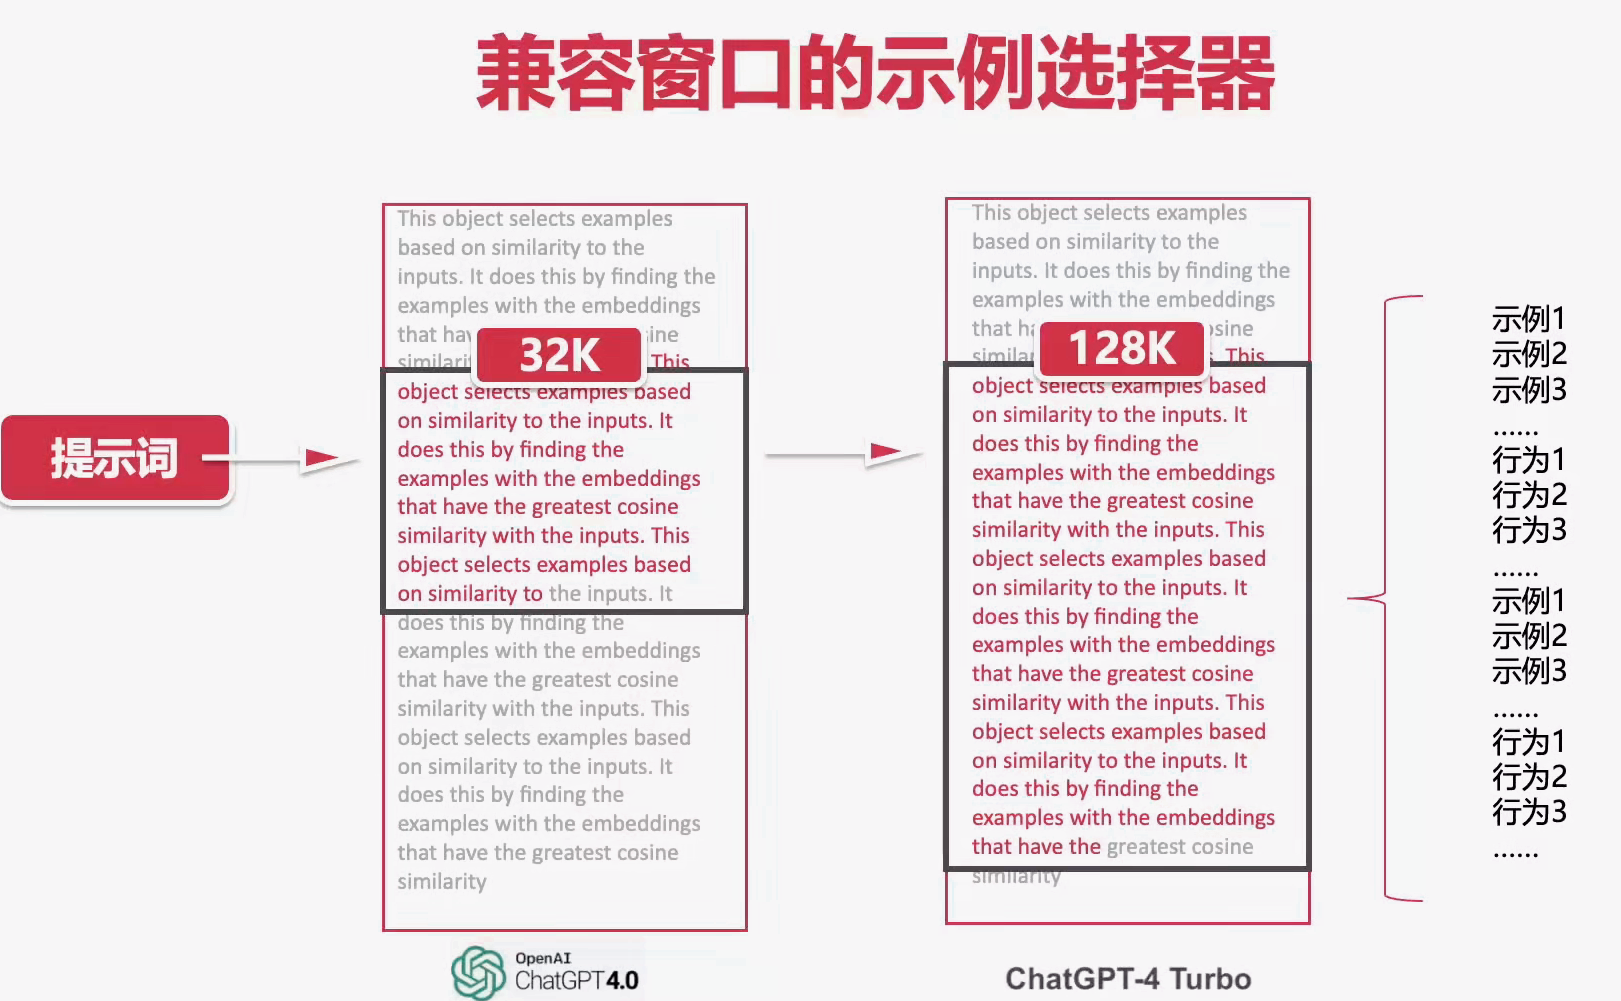

### 示例选择器使用
---
- 根据长度动态选择
- 根据语义相似度动态选择
- 根据最大边际相关性进行选择

#### 根据长度动态选择
---
- 根据用户的输入、提示词总长度来动态计算可容纳的示例个数

In [2]:
# 根据输入的提示词长度综合计算最终长度，智能截取或者添加提示词的示例
# Example of intelligently intercepting or adding prompts by calculating the final length based on the length of the input prompts.
from langchain_core.example_selectors import LengthBasedExampleSelector
from langchain_core.prompts import FewShotPromptTemplate, PromptTemplate

# 假设已经有这么多的提示词示例组：
# Suppose there are so many prompt examples:
examples = [
    {"input":"happy","output":"sad"},
    {"input":"tall","output":"short"},
    {"input":"sunny","output":"gloomy"},
    {"input":"windy","output":"calm"},
    {"input":"高兴","output":"悲伤"},
]

# 构造提示词模板
# Construct prompt template
example_prompt = PromptTemplate(
    input_variables=["input", "output"],
    template="原词：{input}\n反义词：{output}"
)

# 调用长度示例选择器
# Call the length example selector
example_selector = LengthBasedExampleSelector(
    # 传入提示词示例组
    # Pass in the prompt example group
    examples=examples,
    # 传入提示词模板
    example_prompt=example_prompt,
    # 设置格式化的提示词最大长度
    # Set the maximum length of the formatted prompt
    max_length=25,
    # 内置get_text_length，如果默认分词计算方式不满足，可以自己扩展
    # Built-in get_text_length，if the default word segmentation calculation method does not meet the requirements, you can expand it yourself
    # get_text_length:Callable[[str],int] = lambda x:len(re.split("\n| ", x))
)

# 使用小样本提示词模板来实现动态示例的调用
# Use the small sample prompt template to realize the call of dynamic examples
dynamic_prompt = FewShotPromptTemplate(
    example_selector=example_selector,
    example_prompt=example_prompt,
    prefix="给出每个输入词的反义词：",
    suffix="原词：{adjective}\n反义：",
    input_variables=["adjective"]
)

print(dynamic_prompt)

input_variables=['adjective'] input_types={} partial_variables={} example_selector=LengthBasedExampleSelector(examples=[{'input': 'happy', 'output': 'sad'}, {'input': 'tall', 'output': 'short'}, {'input': 'sunny', 'output': 'gloomy'}, {'input': 'windy', 'output': 'calm'}, {'input': '高兴', 'output': '悲伤'}], example_prompt=PromptTemplate(input_variables=['input', 'output'], input_types={}, partial_variables={}, template='原词：{input}\n反义词：{output}'), get_text_length=<function _get_length_based at 0x000001ED6255D640>, max_length=25, example_text_lengths=[2, 2, 2, 2, 2]) example_prompt=PromptTemplate(input_variables=['input', 'output'], input_types={}, partial_variables={}, template='原词：{input}\n反义词：{output}') suffix='原词：{adjective}\n反义：' prefix='给出每个输入词的反义词：'


In [3]:
# 小样本获得所有示例，这样可以有效减少输入的提示词长度
# Small smaple to get all examples, which can effectively reduce the length of the input prompts
print(dynamic_prompt.format(adjective="big"))

给出每个输入词的反义词：

原词：happy
反义词：sad

原词：tall
反义词：short

原词：sunny
反义词：gloomy

原词：windy
反义词：calm

原词：高兴
反义词：悲伤

原词：big
反义：


In [4]:
# 如果输入长度很长，则最终输出会根据长度要求减少
# If the input length is very long, the final output will be reduced according to the length requirements
long_string = "big and huge and massive and large and gigantic and tall and much much much much much bigger then everyone"
print(dynamic_prompt.format(adjective=long_string))

给出每个输入词的反义词：

原词：happy
反义词：sad

原词：tall
反义词：short

原词：big and huge and massive and large and gigantic and tall and much much much much much bigger then everyone
反义：


#### 根据输入的语义相似度动态选择
---
- 筛选示例组中与输入的语义相似度最高的示例
- 本质：将问题与示例嵌入向量空间后进行搜索比对
- 依赖：向量数据库  

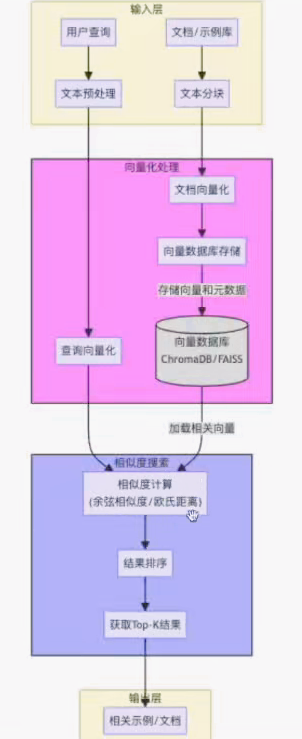

In [6]:
! pip install langchain_community -i https://pypi.tuna.tsinghua.edu.cn/simple

Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


- 选择chromadb向量数据库进行向量化和向量比较

In [40]:
! pip install chromadb -i https://pypi.tuna.tsinghua.edu.cn/simple

Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [120]:
# 使用最大余弦相似度来检索相关示例，以使示例尽量符合输入
# Use the maximum cosine similarity to retrieve relevant examples to make the examples as close as possible to the input

from langchain_community.vectorstores import Chroma
from langchain_core.example_selectors import SemanticSimilarityExampleSelector
from langchain_core.prompts import FewShotPromptTemplate, PromptTemplate
from langchain_openai import OpenAIEmbeddings

import os
from dotenv import load_dotenv

load_dotenv()

example_prompt2 = PromptTemplate(
    input_variables=["input", "output"],
    template="原词：{input}\n反义词：{output}"
)

# 一组示例包含各种性质的反义词
# Examples of a pretend task of creating antonyms.
examples2 = [
    {"input":"happy","output":"sad"},
    {"input":"tall","output":"short"},
    {"input":"energetic","output":"lethargic"},
    {"input":"sunny","output":"gloomy"},
    {"input":"windy","output":"calm"},
]

example_selector2 = SemanticSimilarityExampleSelector.from_examples(
    # 传入示例组
    # Pass in the example group
    examples=examples2,
    # 使用OpenAI嵌入来做相似性搜索
    # Use openAI embeddings for similarity search
    embeddings=OpenAIEmbeddings(model="Qwen/Qwen3-Embedding-8B", openai_api_key=os.getenv("api_key"), openai_api_base=os.getenv("base_url")),
    # 使用Chroma向量数据库来实现对相似结果的过程存储
    # Use the Chrome vector database to implement the process storage of similar results
    vectorstore_cls=Chroma,
    # 指定唯一的 collection_name，防止读取到本地旧的缓存数据
    collection_name="antonym_examples_fresh_v4", 
    # 结果条数
    # Number of results
    k=1,
)

# 使用小样本提示词模板
similar_prompt2 = FewShotPromptTemplate(
    # 传入选择器和模板以及前缀后缀和输入变量
    # Pass in the selector and template, as well as the prefix and suffix and input variables
    example_selector=example_selector2,
    example_prompt=example_prompt2,
    prefix="给出每个输入词的反义词",
    suffix="原词：{adjective}\n反义：",
    input_variables=["adjective"]
)


In [118]:
# 输入一个形容感觉的词语，应该查找近似的 happy/sad 示例
print(similar_prompt2.format(adjective="worried"))

给出每个输入词的反义词

原词：happy
反义词：sad

原词：worried
反义：


In [119]:
# 输入一个形容感觉的词语，应该查找近似的 happy/sad 示例
print(similar_prompt2.format(adjective="晴朗"))

给出每个输入词的反义词

原词：happy
反义词：sad

原词：晴朗
反义：


#### 使用最大边际相关性动态选择示例（MMR）
---
- 筛选示例组中符合MMR规则的示例
- 本质：将问题与示例嵌入向量空间后进行搜索比对
- 依赖：向量数据库
- MMR：是一种在信息检索中常用的方法，它的目标是在相关性和多样性之间找到一个平衡。MMR会首先找出与输入最相似（即余弦相似度最大）的样本。然后再迭代添加样本的过程中，对于与已选择样本过于接近（即相似度过高）的样本进行惩罚。
MMR既能确保选出的样本与输入高度相关，又能保证选出的样本之间有足够的多样性。关注如何再相关性和多样性之间找到一个平衡。

- 依赖FAISS向量数据库的能力，需要安装

In [122]:
! pip install faiss-cpu -i https://pypi.tuna.tsinghua.edu.cn/simple

Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [126]:
# 使用MMR来检索相关示例，以使示例尽量符合输入
# Use MMR to relevant examples to make the examples as close as possible to the inpit

from langchain_community.vectorstores import FAISS
from langchain_core.example_selectors import (
    MaxMarginalRelevanceExampleSelector,
)
from langchain_core.prompts import FewShotPromptTemplate, PromptTemplate
from langchain_openai import OpenAIEmbeddings

import os
from dotenv import load_dotenv

load_dotenv()

# 假设已经有这么多的提示词示例组：
# Suppose there are so many prompt examples:
examples3 = [
    {"input":"happy","output":"sad"},
    {"input":"tall","output":"short"},
    {"input":"sunny","output":"gloomy"},
    {"input":"windy","output":"calm"},
    {"input":"高兴","output":"悲伤"},
]

# 构造提示词模板
# Construct prompt template
example_prompt3 = PromptTemplate(
    input_variables=["input", "output"],
    template="原词：{input}\n反义词：{output}"
)

example_selector3 = MaxMarginalRelevanceExampleSelector.from_examples(
    # 传入示例组
    # Pass in the example group
    examples=examples3,
    # 使用OpenAI嵌入来做相似性搜索
    # Use openAI embeddings for similarity search
    embeddings=OpenAIEmbeddings(model="Qwen/Qwen3-Embedding-8B", openai_api_key=os.getenv("api_key"), openai_api_base=os.getenv("base_url")),
    # 使用Chroma向量数据库来实现对相似结果的过程存储
    # Use the Chrome vector database to implement the process storage of similar results
    vectorstore_cls=FAISS,
    # 结果条数
    # Number of results
    k=2,
)

# 使用小样本提示词模板
mmr_prompt3 = FewShotPromptTemplate(
    example_selector=example_selector3,
    example_prompt=example_prompt3,
    prefix="给出每个输入词的反义词",
    suffix="原词：{adjective}\n反义：",
    input_variables=["adjective"]
)

In [129]:
# 当我们输入一个描述情绪的词语的时候，应该选择同样是描述情绪的一对示例组来填充提示词模板
# When we enter a word describing emotions, we should choose a pair of examples that also describe emotions to fill the prompt template
print(mmr_prompt3.format(adjective="难过"))

给出每个输入词的反义词

原词：happy
反义词：sad

原词：windy
反义词：calm

原词：难过
反义：
